# ESE5023 作业三

数据目录：`Assignment3/data`；结果目录：`Assignment3/results`。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib import font_manager
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
from IPython.display import display

DATA = Path('Assignment3/data')
OUT = Path('Assignment3/results')
OUT.mkdir(parents=True, exist_ok=True)
font = Path('/System/Library/Fonts/Supplemental/Arial Unicode.ttf')
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams.update({'font.size': 10, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False})
coast = list(Reader(DATA / 'coastline/ne_110m_coastline.shp').geometries())

def savefig(name):
    plt.savefig(OUT / f'{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

def area_mean(a):
    return a.weighted(np.cos(np.deg2rad(a.lat.astype(float)))).mean(('lat', 'lon'))

## 1. 全球甲烷

使用 C3S XCH4 v4.3，范围为 2003-01 至 2020-06，共 210 个月，网格为 5° × 5°。文件实际单位为 mol/mol，乘以 $10^9$ 转为 ppb；`fill_value=1e20` 需手动置为缺测。

In [2]:
ch4_ds = xr.open_dataset(DATA / '200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc')
raw = ch4_ds.xch4.sel(time=slice('2003-01', '2020-06')).load()
raw = raw.astype(float)
ch4 = raw.where(~np.isclose(raw, raw.attrs['fill_value'])) * 1e9
ch4.attrs = {'long_name': '柱平均甲烷干空气摩尔分数', 'units': 'ppb'}
print(f'{ch4.sizes["time"]} 个月；有效观测范围 {float(ch4.min()):.1f}–{float(ch4.max()):.1f} ppb')

210 个月；有效观测范围 1567.0–1999.5 ppb


### 1.1 月气候态

**题干：** 计算甲烷各月份的气候态，并用 12 个子图展示。

逐格点对同一月份的有效记录取平均。各图使用相同色标，灰色表示该月份始终缺测。

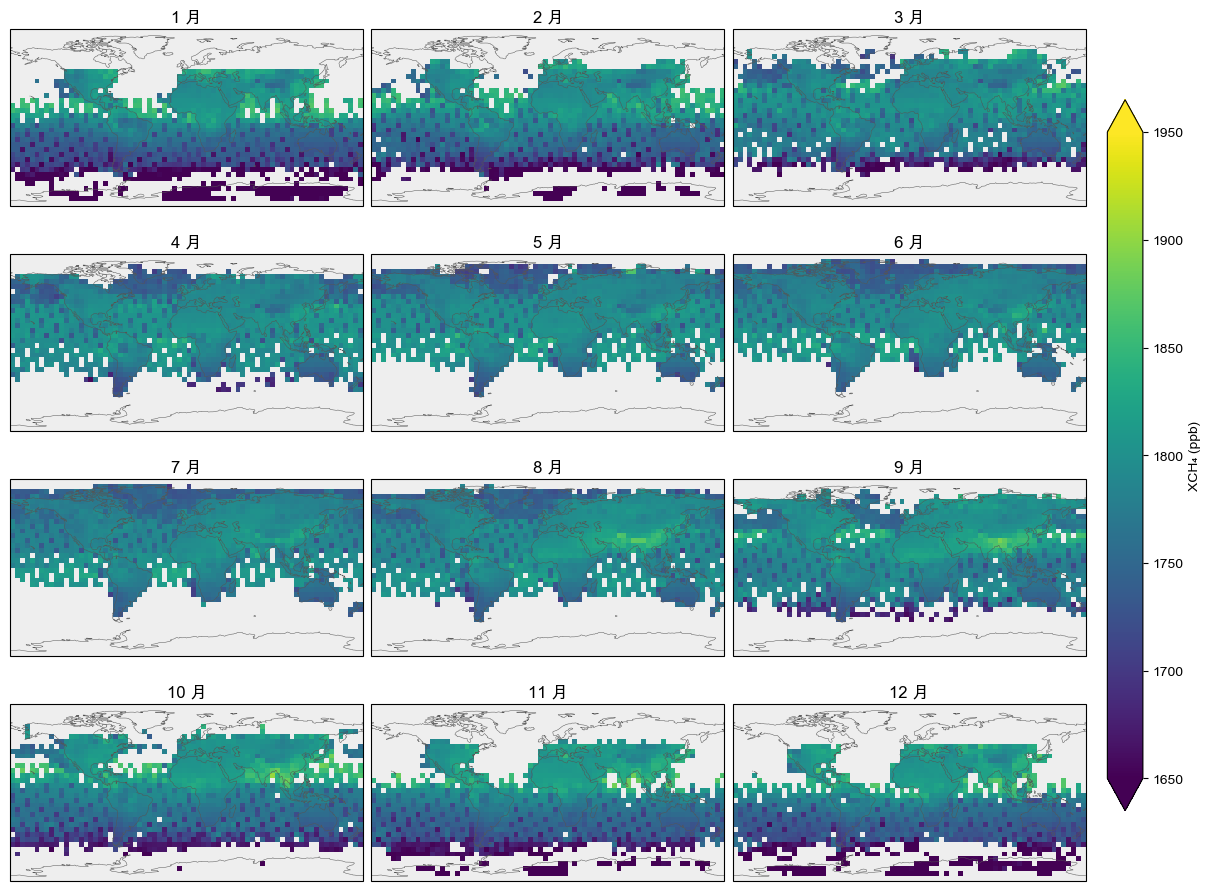

In [3]:
ch4_clim = ch4.groupby('time.month').mean('time')
fig, axes = plt.subplots(4, 3, figsize=(12, 9),
                         subplot_kw={'projection': ccrs.PlateCarree()}, layout='constrained')
for month, ax in enumerate(axes.flat, 1):
    ax.set_facecolor('#eeeeee')
    im = ax.pcolormesh(ch4.lon, ch4.lat, ch4_clim.sel(month=month),
                       transform=ccrs.PlateCarree(), cmap='viridis', vmin=1650, vmax=1950)
    ax.add_geometries(coast, ccrs.PlateCarree(), facecolor='none', edgecolor='#555555', linewidth=.35)
    ax.set_global()
    ax.set_title(f'{month} 月')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.8, pad=.02, label='XCH₄ (ppb)', extend='both')
savefig('1_1_monthly_climatology')
ch4_clim.to_netcdf(OUT / '1_1_monthly_climatology.nc')

### 1.2 全球平均时间序列

**题干：** 绘制 2003-01 至 2020-06 的全球平均甲烷时间序列，描述结果，并与题目提供的 NASA 图对照。

按纬度余弦对有效网格加权，每个月重新计算有效面积的权重总和。下方同时给出覆盖率，避免把观测范围变化误当作浓度变化。

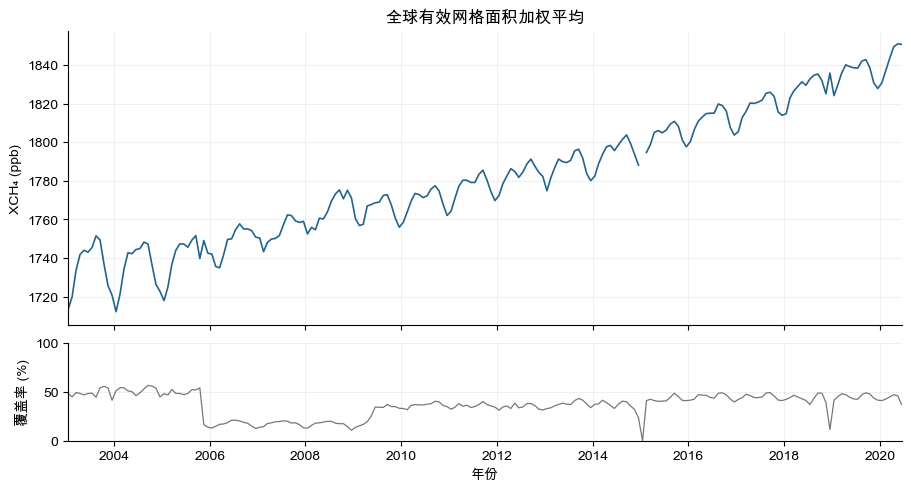

首末月：1713.5、1850.7 ppb；覆盖率：0.0%–56.6%


In [4]:
global_ch4 = area_mean(ch4)
coverage = area_mean(ch4.notnull().astype(float)) * 100
fig, axes = plt.subplots(2, 1, figsize=(9, 4.8), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]}, layout='constrained')
axes[0].plot(ch4.time, global_ch4, color='#23648c', lw=1.2)
axes[0].set(ylabel='XCH₄ (ppb)', title='全球有效网格面积加权平均')
axes[1].plot(ch4.time, coverage, color='#777777', lw=.9)
axes[1].set(ylabel='覆盖率 (%)', xlabel='年份', ylim=(0, 100))
for ax in axes:
    ax.grid(alpha=.18)
    ax.set_xlim(ch4.time.values[0], ch4.time.values[-1])
savefig('1_2_global_methane')
global_table = pd.DataFrame({'xch4_ppb': global_ch4.values, 'coverage_percent': coverage.values},
                            index=pd.DatetimeIndex(ch4.time.values, name='time'))
global_table.to_csv(OUT / '1_2_global_methane.csv')
print(f'首末月：{global_ch4.values[0]:.1f}、{global_ch4.values[-1]:.1f} ppb；覆盖率：{float(coverage.min()):.1f}%–{float(coverage.max()):.1f}%')

整体表现为早期变化较小、2007 年后逐渐上升，并叠加季节波动，与 NASA 参考图的变化方向相近。参考图采用 NOAA 近地面观测，本题为卫星柱平均值，数值不要求重合。有效覆盖随月份变化，因此这里的“全球平均”是可观测网格的面积加权平均。2015 年 1 月全球网格均缺测，保留为空值。

### 1.3 指定位置去季节序列

**题干：** 绘制 15°S、150°W 处 2003-01 至 2020-06 去除季节循环后的甲烷时间序列，并描述结果。

该坐标不在网格中心上，使用 `nearest` 选取 12.5°S、147.5°W 的网格；四个中心等距时，xarray 取较大的坐标值。以该格点各月有效记录均值为气候态，原值减去对应月份均值，缺测月份保留空缺。

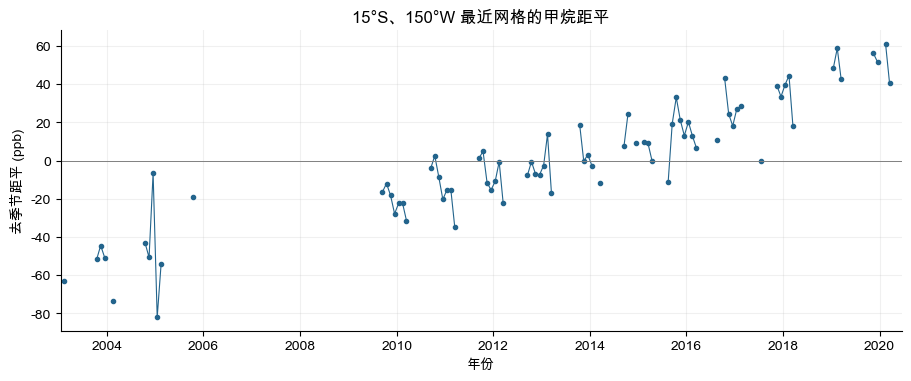

网格中心：-12.5°, -147.5°；有效月份 77/210


,有效月数
month,
1,10
2,13
3,10
4,1
5,0
6,0
7,1
8,2
9,6


In [5]:
point = ch4.sel(lat=-15, lon=-150, method='nearest')
point_clim = point.groupby('time.month').mean('time')
point_anom = point.groupby('time.month') - point_clim
fig, ax = plt.subplots(figsize=(9, 3.7), layout='constrained')
ax.plot(point.time, point_anom, color='#23648c', lw=.8, marker='o', ms=3)
ax.axhline(0, color='grey', lw=.7)
ax.set(xlabel='年份', ylabel='去季节距平 (ppb)', title='15°S、150°W 最近网格的甲烷距平',
       xlim=(ch4.time.values[0], ch4.time.values[-1]))
ax.grid(alpha=.18)
savefig('1_3_point_anomaly')
point_table = pd.DataFrame({'xch4_ppb': point.values, 'anomaly_ppb': point_anom.values},
                           index=pd.DatetimeIndex(point.time.values, name='time'))
point_table.to_csv(OUT / '1_3_point_anomaly.csv')
point_counts = point.groupby('time.month').count()
print(f'网格中心：{float(point.lat)}°, {float(point.lon)}°；有效月份 {int(point.count())}/210')
display(point_counts.to_series().rename('有效月数').to_frame())

去季节后，较早年份多为负距平，较晚年份多为正距平，仍可见长期上升。该网格仅有 77 个有效月份，5、6 月完全缺测，4、7 月各只有一次观测；相应月气候态不稳定，不能把曲线空缺解释为甲烷没有变化。

## 2. Niño 3.4 指数

原网页把本部分两个小题写为 1.1、1.2，这里依次记为 2.1、2.2。使用指定的 ERSST v3b 文件，时间范围为 1960-01 至 2016-12。

### 2.1 区域月气候态与距平

**题干：** 计算 Niño 3.4 区域海表温度的月气候态，并从原始时间序列中减去气候态，得到距平。

区域为 5°S–5°N、170°W–120°W，即 190°E–240°E。按面积加权，东西边界网格各计半格宽度；气候态采用文件全部 1960—2016 年资料。

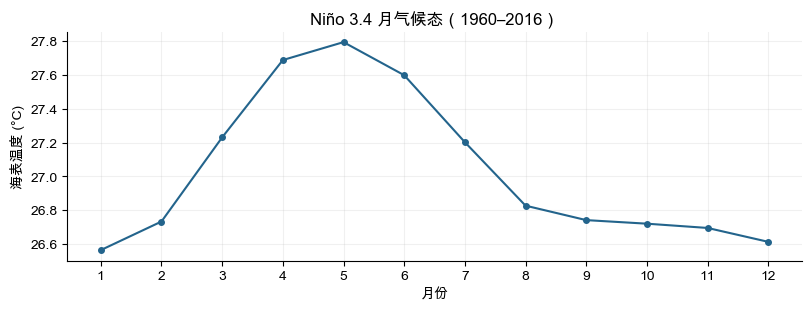

In [6]:
sst_ds = xr.open_dataset(DATA / 'NOAA_NCDC_ERSST_v3b_SST.nc')
sst = sst_ds.sst.sel(lat=slice(-5, 5), lon=slice(190, 240)).load()
lon_width = xr.where((sst.lon == 190) | (sst.lon == 240), 1.0, 2.0)
weights = np.cos(np.deg2rad(sst.lat.astype(float))) * lon_width
nino_sst = sst.weighted(weights).mean(('lat', 'lon'))
nino_clim = nino_sst.groupby('time.month').mean('time')
nino_anom = nino_sst.groupby('time.month') - nino_clim
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.plot(nino_clim.month, nino_clim, '-o', color='#23648c', ms=4)
ax.set(xlabel='月份', ylabel='海表温度 (°C)', title='Niño 3.4 月气候态（1960–2016）', xticks=range(1, 13))
ax.grid(alpha=.18)
savefig('2_1_sst_climatology')
nino_clim.to_series().to_csv(OUT / '2_1_sst_climatology.csv')

### 2.2 Niño 3.4 可视化

**题干：** 绘制计算得到的 Niño 3.4 指数，图形形式参考题目给出的 NOAA 示例。

对月距平作居中的三个月滑动平均，首末月不计算。暖、冷事件分别要求指数达到 +0.5°C、−0.5°C 阈值，并持续至少五个连续的三个月滑动窗口。这里使用固定的全时段基准，不等同于 NOAA 官方滚动基准 ONI。

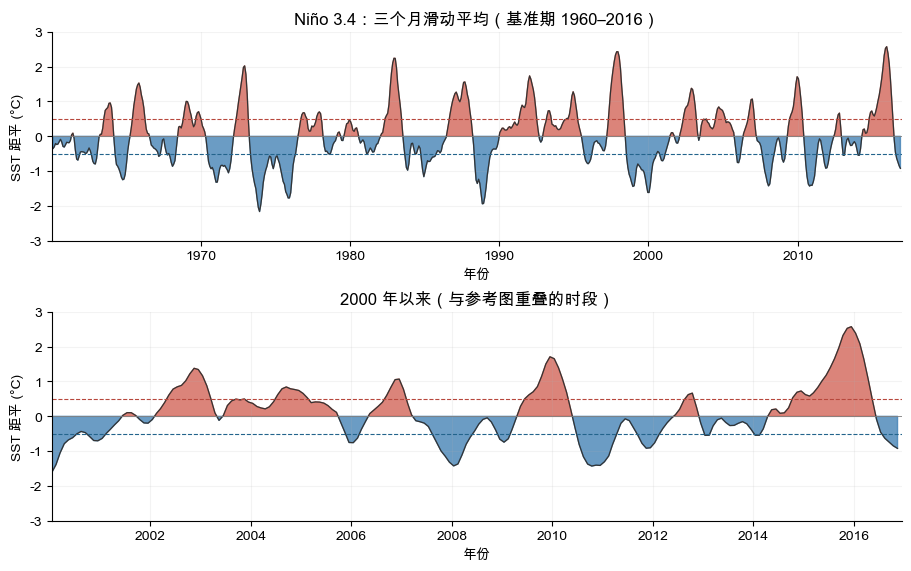

最大值：2.57°C（2015-12）；最小值：-2.16°C（1973-12）


In [7]:
nino = nino_anom.rolling(time=3, center=True, min_periods=3).mean()
index = nino.to_series()
phase = pd.Series(np.select([index >= .5, index <= -.5], [1, -1], default=0), index=index.index)
runs = phase.ne(phase.shift()).cumsum()
event = phase.where(phase.groupby(runs).transform('size') >= 5, 0)
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), layout='constrained')
for ax, start in zip(axes, ['1960', '2000']):
    y = index.loc[start:]
    ax.plot(y.index, y, color='#333333', lw=.9)
    ax.fill_between(y.index, 0, y, where=y >= 0, color='#cf5b4d', alpha=.75, interpolate=True)
    ax.fill_between(y.index, 0, y, where=y < 0, color='#397bb1', alpha=.75, interpolate=True)
    ax.axhline(.5, color='#b7473c', ls='--', lw=.8)
    ax.axhline(-.5, color='#23648c', ls='--', lw=.8)
    ax.axhline(0, color='grey', lw=.6)
    ax.set(xlabel='年份', ylabel='SST 距平 (°C)', ylim=(-3, 3), xlim=(y.index[0], y.index[-1]))
    ax.grid(alpha=.15)
axes[0].set_title('Niño 3.4：三个月滑动平均（基准期 1960–2016）')
axes[1].set_title('2000 年以来（与参考图重叠的时段）')
savefig('2_2_nino34')
nino_table = pd.DataFrame({'sst_c': nino_sst.values, 'anomaly_c': nino_anom.values,
                           'nino34_3month_c': index.values, 'event': event.values}, index=index.index)
nino_table.to_csv(OUT / '2_2_nino34.csv')
print(f'最大值：{index.max():.2f}°C（{index.idxmax():%Y-%m}）；最小值：{index.min():.2f}°C（{index.idxmin():%Y-%m}）')

图中有明显的年际冷暖交替，1982—1983、1997—1998 和 2015—2016 年暖事件较突出；2007—2008、2010—2011 年出现较强冷事件。与参考图重叠部分的主要峰谷位置相近，基准期和数据版本差异会影响幅度。红蓝填色表示距平正负，单次越过阈值并不一定构成事件。

## 3. 东亚月降水

选用 NASA GES DISC 的 GPCPMON v3.3，通过 NOAA NCEI 公共镜像下载相同产品。取 2015—2024 年、10°N–50°N、100°E–140°E 的 `sat_gauge_precip`，保留原始 0.5° 网格和月时间坐标，合并为 NetCDF。区域包括陆地和海洋，单位为 mm/day。

In [8]:
rain_ds = xr.open_dataset(DATA / 'GPCP_v3.3_EastAsia_2015_2024.nc')
rain = rain_ds.sat_gauge_precip.load()
rain = rain.where(rain >= 0)
rain_mean = area_mean(rain)
rain_clim = rain_mean.groupby('time.month').mean('time')
rain_anom = rain_mean.groupby('time.month') - rain_clim
print(f'{rain.sizes["time"]} 个月，{rain.sizes["lat"]} × {rain.sizes["lon"]} 个网格；缺测 {int(rain.isnull().sum())} 个网格月')

120 个月，80 × 80 个网格；缺测 0 个网格月


### 3.1 去除月季节循环

**题干：** 选择一个变量，绘制去除月季节循环后的时间序列。

先对区域降水率作面积加权平均，再减去 2015—2024 年各月均值。

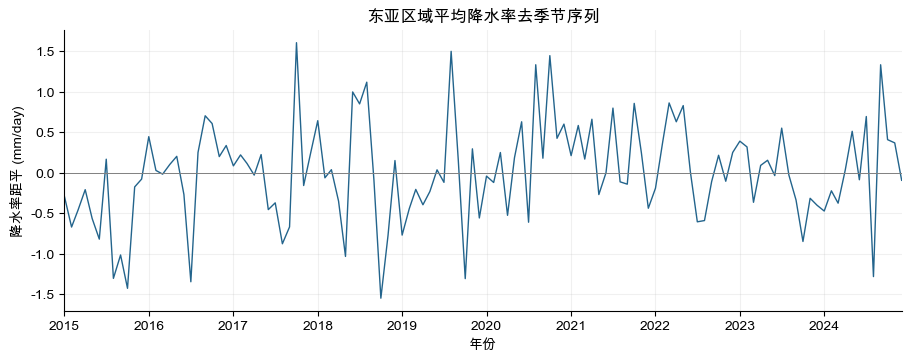

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5), layout='constrained')
ax.plot(rain.time, rain_anom, color='#23648c', lw=1)
ax.axhline(0, color='grey', lw=.7)
ax.set(xlabel='年份', ylabel='降水率距平 (mm/day)', title='东亚区域平均降水率去季节序列',
       xlim=(rain.time.values[0], rain.time.values[-1]))
ax.grid(alpha=.18)
savefig('3_1_precip_anomaly')
rain_table = pd.DataFrame({'precip_mm_day': rain_mean.values, 'anomaly_mm_day': rain_anom.values},
                          index=pd.DatetimeIndex(rain.time.values, name='time'))
rain_table.to_csv(OUT / '3_1_precip_anomaly.csv')

### 3.2 五种图形

**题干：** 利用该 NetCDF 数据集制作至少五幅不同的图。

依次绘制空间分布图、月气候态柱状图、年份—月份距平热图、分月箱线图和距平直方图。

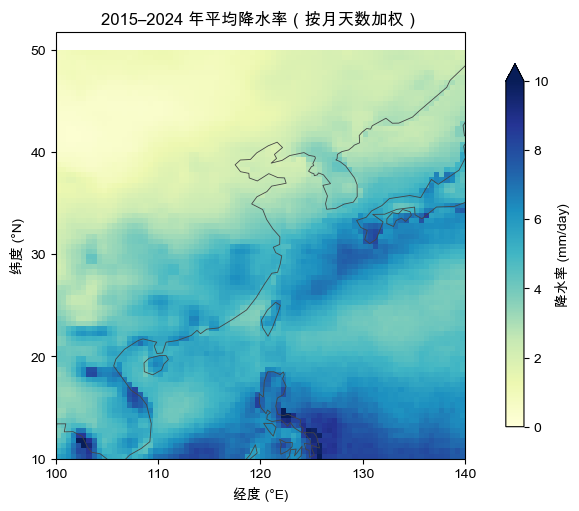

In [10]:
fig, ax = plt.subplots(figsize=(7, 5), subplot_kw={'projection': ccrs.PlateCarree()}, layout='constrained')
mean_map = rain.weighted(rain.time.dt.days_in_month).mean('time')
im = ax.pcolormesh(rain.lon, rain.lat, mean_map, cmap='YlGnBu', vmin=0, vmax=10,
                   transform=ccrs.PlateCarree())
ax.add_geometries(coast, ccrs.PlateCarree(), facecolor='none', edgecolor='#444444', linewidth=.6)
ax.set_extent([100, 140, 10, 50])
ax.set_xticks([100, 110, 120, 130, 140]); ax.set_yticks([10, 20, 30, 40, 50])
ax.set(xlabel='经度 (°E)', ylabel='纬度 (°N)', title='2015–2024 年平均降水率（按月天数加权）')
fig.colorbar(im, ax=ax, shrink=.85, label='降水率 (mm/day)', extend='max')
savefig('3_2a_precip_map')

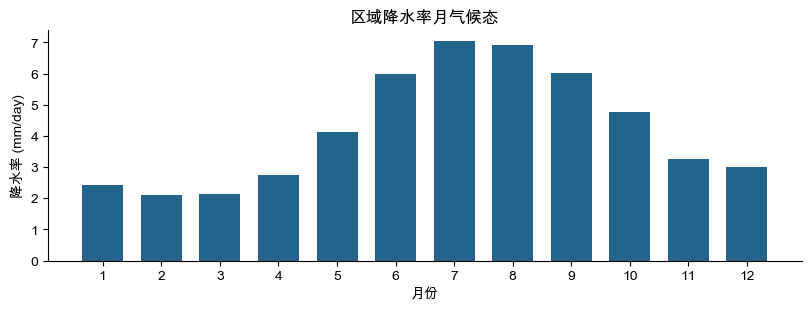

In [11]:
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.bar(rain_clim.month, rain_clim, color='#23648c', width=.7)
ax.set(xlabel='月份', ylabel='降水率 (mm/day)', title='区域降水率月气候态', xticks=range(1, 13))
savefig('3_2b_monthly_bars')

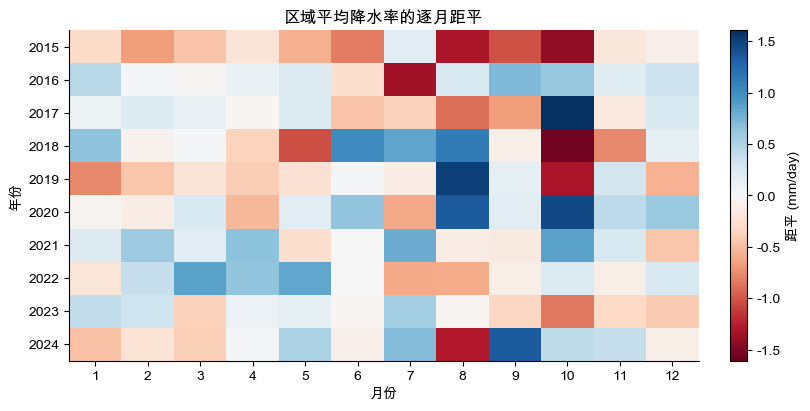

In [12]:
heat = rain_table.assign(year=rain_table.index.year, month=rain_table.index.month).pivot(
    index='year', columns='month', values='anomaly_mm_day')
limit = float(np.abs(heat).to_numpy().max())
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
im = ax.imshow(heat, cmap='RdBu', vmin=-limit, vmax=limit, aspect='auto')
ax.set(xticks=range(12), xticklabels=range(1, 13), yticks=range(len(heat)), yticklabels=heat.index,
       xlabel='月份', ylabel='年份', title='区域平均降水率的逐月距平')
fig.colorbar(im, ax=ax, label='距平 (mm/day)')
savefig('3_2c_anomaly_heatmap')

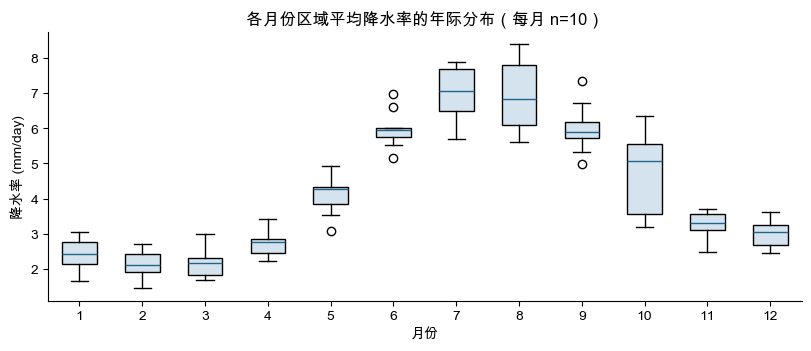

In [13]:
month_values = [rain_mean.where(rain.time.dt.month == m, drop=True).values for m in range(1, 13)]
fig, ax = plt.subplots(figsize=(8, 3.4), layout='constrained')
ax.boxplot(month_values, patch_artist=True, boxprops={'facecolor': '#d4e3ed'},
           medianprops={'color': '#23648c'}, widths=.55)
ax.set(xlabel='月份', ylabel='降水率 (mm/day)', title='各月份区域平均降水率的年际分布（每月 n=10）')
savefig('3_2d_monthly_boxplots')

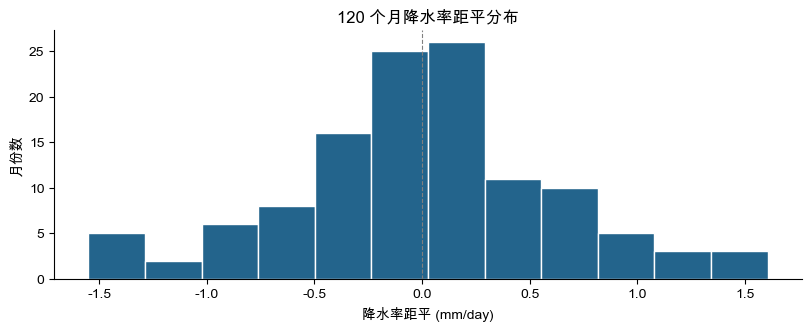

月气候态最大：7 月，7.04 mm/day；最小：2 月，2.11 mm/day
最大正距平：2017-10，1.61 mm/day
最大负距平：2018-10，-1.55 mm/day


In [14]:
fig, ax = plt.subplots(figsize=(8, 3.2), layout='constrained')
ax.hist(rain_anom.values, bins=12, color='#23648c', edgecolor='white')
ax.axvline(0, color='grey', ls='--', lw=.8)
ax.set(xlabel='降水率距平 (mm/day)', ylabel='月份数', title='120 个月降水率距平分布')
savefig('3_2e_anomaly_histogram')
print(f'月气候态最大：{int(rain_clim.idxmax()):d} 月，{float(rain_clim.max()):.2f} mm/day；最小：{int(rain_clim.idxmin()):d} 月，{float(rain_clim.min()):.2f} mm/day')
print(f'最大正距平：{rain_table.anomaly_mm_day.idxmax():%Y-%m}，{rain_table.anomaly_mm_day.max():.2f} mm/day')
print(f'最大负距平：{rain_table.anomaly_mm_day.idxmin():%Y-%m}，{rain_table.anomaly_mm_day.min():.2f} mm/day')

降水存在明显季节性，较湿月份的年际变化也更大。地图显示区域内降水分布不均，区域均值会平滑局地极端；这里分析的是月平均降水率，不是每日降雨强度或雨日数。

## 数据来源

- [作业要求](https://zhu-group.github.io/ese5023/Assignment_03.html)。
- [C3S 甲烷产品](https://www.iup.uni-bremen.de/carbon_ghg/cg_data.html)：University of Bremen，XCH4 v4.3；原始文件下载位置及 SHA-256 见 `Assignment3/data_sources.json`。
- [NASA 甲烷参考图](https://svs.gsfc.nasa.gov/5007)。
- [NOAA ERSST v3b](https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/.version3b/.sst/)；[Niño 3.4 参考图](https://www.ncei.noaa.gov/monitoring-content/teleconnections/eln-5-pg.gif)。
- [NASA GPCPMON v3.3](https://disc.gsfc.nasa.gov/datasets/GPCPMON_3.3/summary)，DOI：10.5067/MEASURES/GPCP/DATA306；[NOAA 公共镜像](https://archive.data.noaa.gov/climatedatarecords/)。
- 地图海岸线：[Natural Earth](https://www.naturalearthdata.com/)，1:110m。

In [15]:
summary = {
    'methane_months': ch4.sizes['time'], 'methane_valid_fraction': float(ch4.notnull().mean()),
    'global_first_ppb': float(global_ch4[0]), 'global_last_ppb': float(global_ch4[-1]),
    'coverage_min_percent': float(coverage.min()), 'coverage_max_percent': float(coverage.max()),
    'point_lat': float(point.lat), 'point_lon': float(point.lon), 'point_valid_months': int(point.count()),
    'nino_max_c': float(index.max()), 'nino_max_month': index.idxmax().strftime('%Y-%m'),
    'nino_min_c': float(index.min()), 'nino_min_month': index.idxmin().strftime('%Y-%m'),
    'sst_clim_min_c': float(nino_clim.min()), 'sst_clim_max_c': float(nino_clim.max()),
    'rain_peak_month': int(rain_clim.idxmax()), 'rain_peak_mm_day': float(rain_clim.max()),
    'rain_low_month': int(rain_clim.idxmin()), 'rain_low_mm_day': float(rain_clim.min()),
    'rain_positive_month': rain_table.anomaly_mm_day.idxmax().strftime('%Y-%m'),
    'rain_positive_mm_day': float(rain_table.anomaly_mm_day.max()),
    'rain_negative_month': rain_table.anomaly_mm_day.idxmin().strftime('%Y-%m'),
    'rain_negative_mm_day': float(rain_table.anomaly_mm_day.min())}
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))

812